# Notebook 03 – Model Development and Training

Train five models under three validation schemes and save their out-of-fold predictions for notebook 04.

| Scheme | Held out | Question |
|---|---|---|
| **A** random points | single S-N points | How well does the model interpolate within curves it has seen? |
| **B** curve held out | whole S-N curves | How well does it predict a new test condition from a known source? |
| **C** article held out | whole source articles | How well does it predict data from an unseen source? (**main result**) |

All schemes use the same 12,666 rows, target, features, fixed model settings, five folds and seed. Preprocessing and models are fitted on the training folds only, and hyperparameters are not tuned.

**Input:** `data/processed/modelling_dataset.csv`.
**Output:** `data/processed/folds.csv`, `results/predictions/*.csv`, `models/*` and the test report.

## 1. Setup

Import the libraries and helper modules, create the output folders and fix the random seeds.

In [1]:
import sys
import json
import time
import subprocess
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import data_utils as du
import feature_utils as fu
import model_utils as mu
import evaluation_utils as eu

eu.set_plot_style()
warnings.filterwarnings("ignore", message="X does not have valid feature names")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PRED_DIR = PROJECT_ROOT / "results" / "predictions"
METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
FIG_DIR = PROJECT_ROOT / "results" / "figures"
MODEL_DIR = PROJECT_ROOT / "models"
for folder in (PRED_DIR, METRICS_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42                      # primary seed, fixed before any model was trained
EXTRA_SEEDS = [43, 44]         # used only to show how much the results move with the fold assignment
PRIMARY_SCHEMES = ["A_random", "B_curve", "C_article"]
SENSITIVITY_SCHEMES = ["C2_article_group", "D_author_cluster"]

print("scikit-learn", sklearn.__version__, "| LightGBM available:", mu.HAVE_LIGHTGBM)
if mu.HAVE_LIGHTGBM:
    import lightgbm
    print("LightGBM", lightgbm.__version__)
print("Gradient-boosting learner used:", mu.MODEL_LABELS["LightGBM"])

scikit-learn 1.9.1 | LightGBM available: True
LightGBM 4.7.0
Gradient-boosting learner used: LightGBM


## 2. Data, target and features

Load the modelling dataset and select the eight tier-0 features. A check stops the notebook if a forbidden column is in the feature list.

In [2]:
data = pd.read_csv(PROCESSED_DIR / "modelling_dataset.csv")

NUMERIC = fu.NUMERIC_TIER0
CATEGORICAL = fu.CATEGORICAL_TIER0
FEATURES = NUMERIC + CATEGORICAL
TARGET = fu.TARGET
fu.assert_features_allowed(FEATURES)

print(f"Rows: {len(data):,} | curves: {data['curve_id'].nunique():,} | articles: {data['article_id'].nunique()}")
print("Target             :", TARGET, f"(mean {data[TARGET].mean():.3f}, standard deviation {data[TARGET].std():.3f})")
print("Numeric features   :", NUMERIC)
print("Categorical features:", CATEGORICAL)
print("Columns in the file that are NOT features:", [c for c in data.columns if c not in FEATURES])
data[FEATURES + [TARGET]].head()

Rows: 12,666 | curves: 1,533 | articles: 440
Target             : log_N (mean 5.321, standard deviation 0.993)
Numeric features   : ['log_sa', 'R', 'log_swt']
Categorical features: ['alloy', 'am_process', 'surface_class', 'heat_treatment_class', 'test_type_class']
Columns in the file that are NOT features: ['row_id', 'curve_id', 'article_id', 'article_group_id', 'author_cluster_id', 'log_N', 'kt', 'log_frequency', 'build_direction_class', 'sa_over_uts', 'log_uts', 'stress_amplitude', 'N', 'sigma_max', 'sigma_mean', 'uts_mpa', 'alloy_family', 'in_near_duplicate_pair', 'test_temperature_c', 'temperature_evidence', 'test_type_raw', 'load_control', 'frequency_text', 'test_machine']


,log_sa,R,log_swt,alloy,am_process,surface_class,heat_treatment_class,test_type_class,log_N
0,2.369151,0.1,2.542545,316L,L-PBF,polished,NHT_or_unreported,axial,4.302067
1,2.334264,0.1,2.507658,316L,L-PBF,polished,NHT_or_unreported,axial,4.704410
2,2.296664,0.1,2.470058,316L,L-PBF,polished,NHT_or_unreported,axial,4.974845
3,2.255313,0.1,2.428706,316L,L-PBF,polished,NHT_or_unreported,axial,5.183543
4,2.209099,0.1,2.382493,316L,L-PBF,polished,NHT_or_unreported,axial,5.432247


## 3. Validation schemes and fold assignment

Shuffle the unique ids of the held-out unit (rows, curves or articles) with the seed and cut them into five folds. The fold table is saved to `data/processed/folds.csv`.

In [3]:
fold_table = pd.concat([
    mu.build_fold_table(data, PRIMARY_SCHEMES, [SEED] + EXTRA_SEEDS),
    mu.build_fold_table(data, ["C2_article_group"], [SEED] + EXTRA_SEEDS),
    mu.build_fold_table(data, ["D_author_cluster"], [SEED]),
], ignore_index=True)
fold_table.to_csv(PROCESSED_DIR / "folds.csv", index=False)
print(f"Saved folds.csv: {len(fold_table):,} rows = {len(data):,} data rows x {fold_table.groupby(['scheme', 'seed']).ngroups} (scheme, seed) combinations\n")

composition = []
for scheme in PRIMARY_SCHEMES + SENSITIVITY_SCHEMES:
    table = mu.fold_composition(data, mu.make_folds(data, scheme, SEED))
    table.insert(0, "scheme", scheme)
    composition.append(table)
composition = pd.concat(composition, ignore_index=True)
composition.to_csv(METRICS_DIR / "fold_composition_seed42.csv", index=False)
composition.pivot(index="fold", columns="scheme", values=["points", "curves", "articles"]).swaplevel(axis=1).sort_index(axis=1)[PRIMARY_SCHEMES + SENSITIVITY_SCHEMES]

Saved folds.csv: 164,658 rows = 12,666 data rows x 13 (scheme, seed) combinations



scheme A_random                B_curve               C_article               C2_article_group               D_author_cluster              
       articles curves points articles curves points  articles curves points         articles curves points         articles curves points
fold                                                                                                                                      
0           423   1201   2534      218    307   2428        88    316   2558               91    340   2879               65    197   1669
1           421   1215   2533      212    307   2488        88    292   2406               84    248   2077              213    792   6563
2           416   1182   2533      210    307   2540        88    310   2745               91    313   2302               45    141   1266
3           426   1184   2533      214    306   2587        88    309   2434               87    311   2545               63    208   1593
4           421   1195   2533      217    306   2623        88    306   2523               87    321   2863               54    195   1575

### 3.1 What a held-out point can still see in training

For each scheme, count the share of held-out points whose curve, article, re-publication group or author cluster also appears in the training set.

In [4]:
rows = []
for scheme in PRIMARY_SCHEMES + SENSITIVITY_SCHEMES:
    folds = mu.make_folds(data, scheme, SEED)
    seen = {"same curve": 0, "same article": 0, "same re-publication group": 0, "same author cluster": 0}
    for fold in range(mu.N_FOLDS):
        train, test = data[folds != fold], data[folds == fold]
        if scheme != "A_random":
            mu.assert_group_disjoint(train, test, scheme)       # raises on group leakage
        seen["same curve"] += test["curve_id"].isin(set(train["curve_id"])).sum()
        seen["same article"] += test["article_id"].isin(set(train["article_id"])).sum()
        seen["same re-publication group"] += test["article_group_id"].isin(set(train["article_group_id"])).sum()
        seen["same author cluster"] += test["author_cluster_id"].isin(set(train["author_cluster_id"])).sum()
    rows.append({"scheme": eu.SCHEME_LABELS[scheme], **{f"{k} in training, % of held-out points": round(100 * v / len(data), 1) for k, v in seen.items()}})
overlap = pd.DataFrame(rows)
overlap.to_csv(METRICS_DIR / "train_test_overlap_by_scheme.csv", index=False)
overlap

,scheme,"same curve in training, % of held-out points","same article in training, % of held-out points","same re-publication group in training, % of held-out points","same author cluster in training, % of held-out points"
0,A: random points,99.7,100.0,100.0,100.0
1,B: curve held out,0.0,89.1,90.1,97.5
2,C: article held out,0.0,0.0,14.3,77.0
3,C2: re-publication group held out,0.0,0.0,0.0,76.4
4,D: author cluster held out,0.0,0.0,0.0,0.0


*Note:* under random splits almost every test point has its own curve in training; with curves held out, 89% still have their own article in training. Only scheme C removes the article completely.

## 4. Models and fixed settings

Create the five models with their fixed settings and save the configuration to `models/model_config.json`.

| # | Model | Settings (fixed in advance) | Role |
|---|---|---|---|
| 1 | **Basquin baseline** | log10(N) = A + B·log10(σa), least squares. One line per alloy if the training fold has at least 30 points from 3 curves of that alloy *and* the slope is negative; otherwise one pooled line | Physics reference |
| 2 | **Ridge regression** | alpha = 1.0; numeric inputs standardised; categoricals one-hot encoded | Linear reference |
| 3 | **Random Forest** | 300 trees, `min_samples_leaf` = 3 | Non-linear baseline |
| 4 | **LightGBM** | 400 trees, learning rate 0.05, 31 leaves, `min_child_samples` 20, row and column subsample 0.8 | Main direct learner |
| 5 | **Basquin-anchored residual** | Model 1 plus model 4 trained on the residuals y − y_Basquin | Tests hypothesis H2 |

Preprocessing inside each training fold: median imputation, scaling (Ridge only) and one-hot encoding, with categories that have fewer than 20 training rows grouped as "infrequent".

In [5]:
for name in mu.MODEL_ORDER:
    print(f"--- {name}: {mu.MODEL_LABELS[name]}")
    print(mu.make_model(name, NUMERIC, CATEGORICAL, SEED), "\n")

model_config = {
    "target": TARGET, "numeric_features": NUMERIC, "categorical_features": CATEGORICAL,
    "primary_seed": SEED, "extra_seeds": EXTRA_SEEDS, "n_folds": mu.N_FOLDS,
    "schemes": {s: mu.SCHEME_GROUP_COLUMN[s] for s in PRIMARY_SCHEMES + SENSITIVITY_SCHEMES},
    "ridge": mu.RIDGE_PARAMS, "random_forest": mu.RF_PARAMS, "lightgbm": mu.LGBM_PARAMS,
    "gradient_boosting_implementation": "LightGBM" if mu.HAVE_LIGHTGBM else "sklearn HistGradientBoostingRegressor (fallback)",
    "one_hot_min_frequency": mu.ONE_HOT_MIN_FREQUENCY,
    "preprocessing": {"numeric": "median imputation; standard scaling for Ridge only",
                      "categorical": "one-hot, dense matrix (OneHotEncoder sparse_output=False), handle_unknown='infrequent_if_exist'",
                      "note": "Random Forest predictions depend on the matrix format (dense versus sparse) at the level of its own randomness"},
    "basquin": {"min_points_per_alloy": mu.BASQUIN_MIN_POINTS, "min_curves_per_alloy": mu.BASQUIN_MIN_CURVES, "slope_must_be_negative": True},
    "hyperparameter_tuning": "none (settings fixed in advance)",
}
du.save_json(model_config, MODEL_DIR / "model_config.json")

--- Basquin: Basquin (per alloy)
BasquinRegressor() 

--- Ridge: Ridge
Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['log_sa', 'R', 'log_swt']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                min_frequency=20,
                                                                sparse_output=False),
                                                  ['alloy', 'am_process',
                        

### 4.1 Basquin baseline on one training fold

Fit the Basquin baseline on fold 0 of scheme C to show the per-alloy and pooled-line rules, and plot the Ti-6Al-4V example.

Pooled line (all training rows): log10(N) = 7.24 + (-0.80) * log10(sigma_a)
Alloys in this training fold: 82 | with their own line: 21
Decisions: {'pooled (too few points or curves)': 58, 'per-alloy': 21, 'pooled (slope not negative)': 3}
Held-out rows of fold 0 predicted with the pooled line: 15.9%


,alloy,train_points,train_curves,A,B,decision
72,Ti-6Al-4V,3889,440,7.158,-0.731,per-alloy
49,IN718,1156,134,8.513,-1.256,per-alloy
7,316L,1102,134,9.026,-1.557,per-alloy
20,AlSi10Mg,1033,125,10.056,-2.275,per-alloy
1,17-4 PH,357,38,11.239,-2.404,per-alloy
2,18Ni300,286,47,4.067,0.513,pooled (slope not negative)
53,Maraging Steel,231,26,8.202,-1.244,per-alloy
0,15-5 PH,131,12,15.939,-4.053,per-alloy
52,Maraging Stainless Steel CX,106,9,3.985,0.586,pooled (slope not negative)
48,IN625,99,15,9.514,-1.673,per-alloy


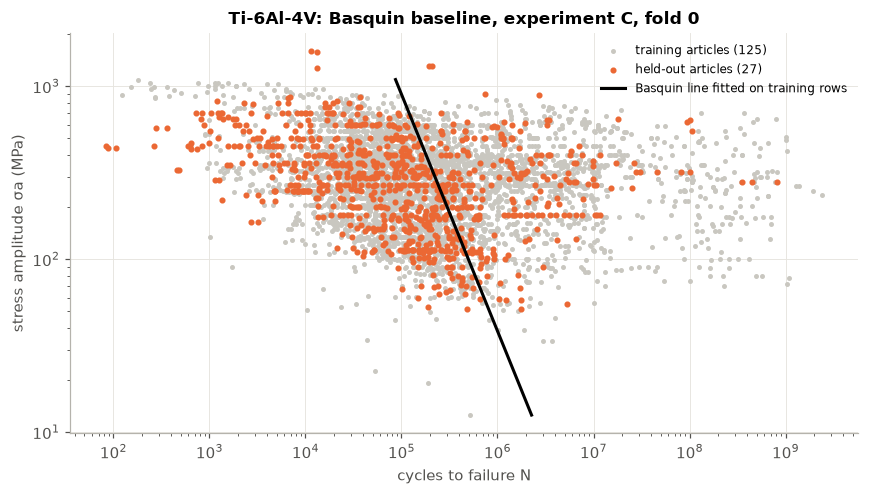

In [6]:
folds_c = mu.make_folds(data, "C_article", SEED)
train0, test0 = data[folds_c != 0], data[folds_c == 0]

basquin0 = mu.BasquinRegressor().fit(train0[FEATURES], train0[TARGET], curve_ids=train0["curve_id"])
fit_log0 = pd.DataFrame(basquin0.fit_log_).sort_values("train_points", ascending=False)
print(f"Pooled line (all training rows): log10(N) = {basquin0.pooled_[0]:.2f} + ({basquin0.pooled_[1]:.2f}) * log10(sigma_a)")
print(f"Alloys in this training fold: {len(fit_log0)} | with their own line: {len(basquin0.per_alloy_)}")
print("Decisions:", fit_log0["decision"].value_counts().to_dict())
pooled_share = basquin0.uses_pooled(test0[FEATURES]).mean()
print(f"Held-out rows of fold 0 predicted with the pooled line: {100 * pooled_share:.1f}%")
display(fit_log0.head(12).round(3))

# The same fold as a picture: Ti-6Al-4V training points, held-out points and the fitted line.
alloy = "Ti-6Al-4V"
fig, ax = plt.subplots(figsize=(8, 4.6))
tr, te = train0[train0["alloy"] == alloy], test0[test0["alloy"] == alloy]
ax.scatter(tr["N"], tr["stress_amplitude"], s=5, color="#c9c7c0", label=f"training articles ({tr['article_id'].nunique()})", rasterized=True)
ax.scatter(te["N"], te["stress_amplitude"], s=9, color=eu.PALETTE[1], label=f"held-out articles ({te['article_id'].nunique()})")
grid = pd.DataFrame({"log_sa": np.linspace(tr["log_sa"].min(), tr["log_sa"].max(), 50), "alloy": alloy})
ax.plot(10 ** basquin0.predict(grid), 10 ** grid["log_sa"], color="black", lw=2, label="Basquin line fitted on training rows")
ax.set(xscale="log", yscale="log", xlabel="cycles to failure N", ylabel="stress amplitude σa (MPa)", title=f"{alloy}: Basquin baseline, experiment C, fold 0")
ax.legend(fontsize=8)
fig.tight_layout()
eu.save_figure(fig, FIG_DIR / "03_basquin_fold_example.png")
plt.show()

*Note:* pooled literature data give much flatter slopes than single-material Basquin curves, and some alloys even get a positive slope, so the Basquin anchor is weak.

## 5. Cross-validated training: experiments A, B and C

Train every model on the training folds only and predict the held-out fold, giving one out-of-fold prediction per row, model and scheme.

In [7]:
def run_schemes(frame, schemes, model_names, numeric, categorical, seed, label):
    # Run several schemes and stack their out-of-fold predictions.
    predictions, logs = [], []
    for scheme in schemes:
        start = time.time()
        pred, log = mu.run_cv(frame, scheme, model_names, numeric, categorical, seed=seed, verbose=False)
        predictions.append(pred)
        logs.append(log)
        print(f"{label}: {scheme:17s} seed {seed}: {len(model_names)} models x {mu.N_FOLDS} folds in {time.time() - start:4.0f} s")
    return pd.concat(predictions, ignore_index=True), pd.concat(logs, ignore_index=True)

primary_predictions, basquin_log = run_schemes(data, PRIMARY_SCHEMES, mu.MODEL_ORDER, NUMERIC, CATEGORICAL, SEED, "primary")
primary_predictions.to_csv(PRED_DIR / "oof_predictions_primary.csv", index=False)
basquin_log.to_csv(METRICS_DIR / "basquin_fit_log_primary.csv", index=False)

# Every row must have exactly one prediction per scheme and model.
counts = primary_predictions.groupby(["scheme", "model"])["row_id"].agg(["size", "nunique"])
assert (counts["size"] == len(data)).all() and (counts["nunique"] == len(data)).all()
print(f"\nSaved {len(primary_predictions):,} out-of-fold predictions = {len(data):,} rows x {len(PRIMARY_SCHEMES)} schemes x {len(mu.MODEL_ORDER)} models")
primary_predictions.head()

primary: A_random          seed 42: 5 models x 5 folds in   25 s


primary: B_curve           seed 42: 5 models x 5 folds in   23 s


primary: C_article         seed 42: 5 models x 5 folds in   26 s



Saved 189,990 out-of-fold predictions = 12,666 rows x 3 schemes x 5 models


,row_id,curve_id,article_id,alloy,scheme,seed,fold,model,y_true,y_pred,basquin_pooled_fallback
0,4,1,10.1002/adem.202200751,316L,A_random,42,0,Basquin,5.432247,5.604725,False
1,11,2,10.1002/adem.202200751,316L + Nitrogen,A_random,42,0,Basquin,5.884014,5.484088,True
2,16,3,10.1007/978-3-030-05861-6_36,Ti-6Al-4V,A_random,42,0,Basquin,4.828557,5.255871,False
3,29,4,10.1007/978-3-030-05861-6_36,Ti-6Al-4V,A_random,42,0,Basquin,5.027122,5.517784,False
4,32,5,10.1007/978-3-030-05861-6_36,Ti-6Al-4V,A_random,42,0,Basquin,4.680774,5.255564,False


### 5.1 Preliminary error table

A first look at the RMSE of log10(Nf) and the inflation factors. The full evaluation is in notebook 04.

In [8]:
preliminary = eu.metrics_table(primary_predictions)
rmse_wide = preliminary.pivot(index="model", columns="scheme", values="rmse").loc[mu.MODEL_ORDER, PRIMARY_SCHEMES]
rmse_wide["inflation B/A"] = rmse_wide["B_curve"] / rmse_wide["A_random"]
rmse_wide["inflation C/A"] = rmse_wide["C_article"] / rmse_wide["A_random"]
print(f"Reference: standard deviation of the target = {data[TARGET].std():.3f} (RMSE of always predicting the mean)")
display(rmse_wide.round(3))

fallback = (primary_predictions[primary_predictions["model"] == "Basquin"].groupby("scheme")["basquin_pooled_fallback"].mean() * 100).round(1)
print("Basquin: share of held-out rows predicted with the pooled fallback line, %:")
print(fallback.to_string())

Reference: standard deviation of the target = 0.993 (RMSE of always predicting the mean)


scheme,A_random,B_curve,C_article,inflation B/A,inflation C/A
model,,,,,
Basquin,0.938,0.954,0.992,1.018,1.058
Ridge,0.897,0.951,0.970,1.060,1.081
RandomForest,0.647,0.797,0.927,1.231,1.432
LightGBM,0.673,0.787,0.924,1.170,1.373
BasquinResidual,0.667,0.788,0.940,1.181,1.408


Basquin: share of held-out rows predicted with the pooled fallback line, %:
scheme
A_random     12.5
B_curve      13.9
C_article    16.8


## 6. Two more seeds

Repeat the training with seeds 43 and 44 to see how much the results depend on the fold assignment.

In [9]:
seed_predictions = []
for seed in EXTRA_SEEDS:
    pred, _ = run_schemes(data, PRIMARY_SCHEMES, mu.MODEL_ORDER, NUMERIC, CATEGORICAL, seed, "extra seed")
    seed_predictions.append(pred)
seed_predictions = pd.concat(seed_predictions, ignore_index=True)
seed_predictions.to_csv(PRED_DIR / "oof_predictions_extra_seeds.csv", index=False)

all_seeds = pd.concat([primary_predictions, seed_predictions], ignore_index=True)
by_seed = eu.metrics_table(all_seeds, by=("model", "scheme", "seed")).pivot_table(index=["model", "seed"], columns="scheme", values="rmse")
by_seed.loc[mu.MODEL_ORDER, PRIMARY_SCHEMES].round(3)

extra seed: A_random          seed 43: 5 models x 5 folds in   23 s


extra seed: B_curve           seed 43: 5 models x 5 folds in   22 s


extra seed: C_article         seed 43: 5 models x 5 folds in   21 s


extra seed: A_random          seed 44: 5 models x 5 folds in   21 s


extra seed: B_curve           seed 44: 5 models x 5 folds in   20 s


extra seed: C_article         seed 44: 5 models x 5 folds in   21 s


scheme                A_random  B_curve  C_article
model           seed                              
Basquin         42       0.938    0.954      0.992
                43       0.939    0.955      1.000
                44       0.940    0.952      0.999
Ridge           42       0.897    0.951      0.970
                43       0.896    0.918      0.983
                44       0.897    0.917      0.983
RandomForest    42       0.647    0.797      0.927
                43       0.653    0.788      0.930
                44       0.655    0.788      0.914
LightGBM        42       0.673    0.787      0.924
                43       0.675    0.785      0.923
                44       0.675    0.784      0.907
BasquinResidual 42       0.667    0.788      0.940
                43       0.670    0.788      0.939
                44       0.671    0.783      0.925

## 7. Sensitivity runs

Each run changes one choice; the results are evaluated in notebook 04. All use seed 42 and the same fixed settings.

| Run | What changes |
|---|---|
| S1 | Held-out unit: re-publication groups (C2, three seeds) and author clusters (D) |
| S2 | LightGBM constrained so that life never rises with stress |
| S3 | Feature tier 1 (adds Kt, frequency, build direction) |
| S4 | UTS subset: tier 0 against tier 2 (adds σa/UTS and UTS) on the same rows |
| S5 | Run-outs kept and treated as failures at their recorded life |

Run S1, S2 and S3.

In [10]:
# S1: stricter held-out units, same rows and models.
group_predictions, _ = run_schemes(data, SENSITIVITY_SCHEMES, mu.MODEL_ORDER, NUMERIC, CATEGORICAL, SEED, "S1 groups")
# Regrouping articles reshuffles every fold, so C2 is also run with the two extra seeds:
# only then can the effect of the grouping be told apart from the luck of one fold assignment.
for seed in EXTRA_SEEDS:
    extra, _ = run_schemes(data, ["C2_article_group"], mu.MODEL_ORDER, NUMERIC, CATEGORICAL, seed, "S1 groups")
    group_predictions = pd.concat([group_predictions, extra], ignore_index=True)
group_predictions.to_csv(PRED_DIR / "oof_predictions_group_sensitivity.csv", index=False)

# S2: monotone-constrained gradient boosting (log_swt left out, see MonotoneGBM in model_utils.py).
monotone_predictions, _ = run_schemes(data, PRIMARY_SCHEMES, ["LightGBM_monotone"], NUMERIC, CATEGORICAL, SEED, "S2 monotone")
monotone_predictions.to_csv(PRED_DIR / "oof_predictions_monotone.csv", index=False)

# S3: feature tier 1 on the full dataset.
tier1_models = ["Ridge", "RandomForest", "LightGBM", "BasquinResidual"]
tier1_predictions, _ = run_schemes(data, PRIMARY_SCHEMES, tier1_models, fu.NUMERIC_TIER1, fu.CATEGORICAL_TIER1, SEED, "S3 tier 1")
tier1_predictions.insert(0, "feature_tier", "tier1")
tier1_predictions.to_csv(PRED_DIR / "oof_predictions_tier1.csv", index=False)

S1 groups: C2_article_group  seed 42: 5 models x 5 folds in   22 s


S1 groups: D_author_cluster  seed 42: 5 models x 5 folds in   23 s


S1 groups: C2_article_group  seed 43: 5 models x 5 folds in   20 s


S1 groups: C2_article_group  seed 44: 5 models x 5 folds in   24 s


S2 monotone: A_random          seed 42: 1 models x 5 folds in    2 s


S2 monotone: B_curve           seed 42: 1 models x 5 folds in    2 s


S2 monotone: C_article         seed 42: 1 models x 5 folds in    2 s


S3 tier 1: A_random          seed 42: 4 models x 5 folds in   25 s


S3 tier 1: B_curve           seed 42: 4 models x 5 folds in   32 s


S3 tier 1: C_article         seed 42: 4 models x 5 folds in   31 s


Run S4 and S5.

In [11]:
# S4: the subset with UTS. Tier 0 and tier 2 are run on exactly the same rows and folds.
uts_data = data[data["uts_mpa"].notna()].reset_index(drop=True)
print(f"UTS subset: {len(uts_data):,} points, {uts_data['curve_id'].nunique():,} curves, {uts_data['article_id'].nunique()} articles")
uts_parts = []
for tier, numeric, categorical in [("tier0", fu.NUMERIC_TIER0, fu.CATEGORICAL_TIER0), ("tier2", fu.NUMERIC_TIER2, fu.CATEGORICAL_TIER2)]:
    pred, _ = run_schemes(uts_data, PRIMARY_SCHEMES, ["Ridge", "RandomForest", "LightGBM", "BasquinResidual"], numeric, categorical, SEED, f"S4 {tier}")
    pred.insert(0, "feature_tier", tier)
    uts_parts.append(pred)
uts_predictions = pd.concat(uts_parts, ignore_index=True)
uts_predictions.to_csv(PRED_DIR / "oof_predictions_uts_subset.csv", index=False)

# S5: run-outs kept as if they were failures at the recorded life.
with_runouts = pd.read_csv(PROCESSED_DIR / "sn_cohort_with_runouts.csv")
assert "is_runout" not in FEATURES
print(f"\nCohort with run-outs: {len(with_runouts):,} points, of which {int(with_runouts['is_runout'].sum()):,} run-outs")
runout_predictions, _ = run_schemes(with_runouts, PRIMARY_SCHEMES, mu.MODEL_ORDER, NUMERIC, CATEGORICAL, SEED, "S5 run-outs")
runout_predictions = runout_predictions.merge(with_runouts[["row_id", "is_runout"]], on="row_id", how="left")
runout_predictions.to_csv(PRED_DIR / "oof_predictions_with_runouts.csv", index=False)

print("\nPrediction files written:")
for path in sorted(PRED_DIR.glob("*.csv")):
    print(f"  {path.name:45s} {sum(1 for _ in open(path, encoding='utf8')) - 1:>8,} rows")

UTS subset: 6,674 points, 785 curves, 244 articles


S4 tier0: A_random          seed 42: 4 models x 5 folds in   13 s


S4 tier0: B_curve           seed 42: 4 models x 5 folds in   12 s


S4 tier0: C_article         seed 42: 4 models x 5 folds in   12 s


S4 tier2: A_random          seed 42: 4 models x 5 folds in   14 s


S4 tier2: B_curve           seed 42: 4 models x 5 folds in   19 s


... (4 outputs left out)

S5 run-outs: C_article         seed 42: 5 models x 5 folds in   31 s



Prediction files written:
  oof_predictions_extra_seeds.csv                379,980 rows


  oof_predictions_group_sensitivity.csv          253,320 rows
  oof_predictions_monotone.csv                    37,998 rows
  oof_predictions_primary.csv                    189,990 rows


  oof_predictions_tier1.csv                      151,992 rows
  oof_predictions_uts_subset.csv                 160,176 rows
  oof_predictions_with_runouts.csv               216,210 rows


### 7.1 Supplementary investigation A: cross-fitted Basquin anchor

Train a version of the hybrid whose corrector learns from Basquin residuals fitted without each row's own article (inner article-grouped folds). The original hybrid is unchanged.

In [12]:
crossfit_parts = []
for seed in [SEED] + EXTRA_SEEDS:
    pred, _ = run_schemes(data, PRIMARY_SCHEMES, ["BasquinResidualCrossFitted"], NUMERIC, CATEGORICAL, seed, f"A cross-fitted, seed {seed}")
    crossfit_parts.append(pred)
crossfit_predictions = pd.concat(crossfit_parts, ignore_index=True)
crossfit_predictions.to_csv(PRED_DIR / "oof_predictions_crossfitted_residual.csv", index=False)
print(f"Saved oof_predictions_crossfitted_residual.csv: {len(crossfit_predictions):,} rows")

# What the corrector learns from (article held out, seed 42): residuals of the anchor on the OUTER TRAINING rows,
# in-sample (the original hybrid) against cross-fitted (investigation A), by the alloy's status in that training fold.
well_represented = data.groupby("alloy")["article_id"].nunique().loc[lambda s: s >= 15].index
outer = mu.make_folds(data, "C_article", SEED).to_numpy()
sums = {}
for k in range(mu.N_FOLDS):
    train = data[outer != k].reset_index(drop=True)
    y_train = train[TARGET].to_numpy()
    inner, n_inner = mu.inner_group_folds(train["article_id"], mu.N_FOLDS, SEED)
    cross_fitted = np.empty(len(train))
    for f in range(n_inner):
        held = inner == f
        line = mu.BasquinRegressor().fit(train[~held], y_train[~held], curve_ids=train.loc[~held, "curve_id"].to_numpy())
        cross_fitted[held] = line.predict(train[held])
    full = mu.BasquinRegressor().fit(train, y_train, curve_ids=train["curve_id"].to_numpy())
    in_sample = full.predict(train)
    group = np.select([train["alloy"].isin(well_represented).to_numpy(), train["alloy"].isin(list(full.per_alloy_)).to_numpy()],
                      ["1 well-represented alloy (15+ articles)", "2 other alloy with its own line"], default="3 alloy on the pooled line")
    for g in np.unique(group):
        m = group == g
        s = sums.setdefault(g, [0, 0.0, 0.0])
        s[0] += int(m.sum()); s[1] += float(np.sum((y_train[m] - in_sample[m]) ** 2)); s[2] += float(np.sum((y_train[m] - cross_fitted[m]) ** 2))
residual_targets = pd.DataFrame([{"alloy group in the outer training fold": g, "training-row evaluations": n,
                                  "RMSE of in-sample anchor residuals": np.sqrt(a / n), "RMSE of cross-fitted anchor residuals": np.sqrt(b / n)}
                                 for g, (n, a, b) in sorted(sums.items())])
residual_targets.to_csv(METRICS_DIR / "investigation_A_residual_targets.csv", index=False)
residual_targets

A cross-fitted, seed 42: A_random          seed 42: 1 models x 5 folds in    4 s


A cross-fitted, seed 42: B_curve           seed 42: 1 models x 5 folds in    3 s


A cross-fitted, seed 42: C_article         seed 42: 1 models x 5 folds in    3 s


A cross-fitted, seed 43: A_random          seed 43: 1 models x 5 folds in    4 s


A cross-fitted, seed 43: B_curve           seed 43: 1 models x 5 folds in    4 s


A cross-fitted, seed 43: C_article         seed 43: 1 models x 5 folds in    3 s


A cross-fitted, seed 44: A_random          seed 44: 1 models x 5 folds in    3 s


A cross-fitted, seed 44: B_curve           seed 44: 1 models x 5 folds in    3 s


A cross-fitted, seed 44: C_article         seed 44: 1 models x 5 folds in    3 s


Saved oof_predictions_crossfitted_residual.csv: 113,994 rows


,alloy group in the outer training fold,training-row evaluations,RMSE of in-sample anchor residuals,RMSE of cross-fitted anchor residuals
0,1 well-represented alloy (15+ articles),37792,0.965018,0.985345
1,2 other alloy with its own line,6467,0.707299,1.052757
2,3 alloy on the pooled line,6405,0.936643,0.962959


*Note:* for moderately represented alloys the in-sample residuals are about a third smaller than the cross-fitted ones. Notebook 04 (section 11.7) tests whether this matters.

### 7.2 Supplementary investigation B: test regimes and one-feature ablation

Add test-regime labels (VHCF tag, resonance tag, kHz test, ultrasonic, displacement control), train tier 0 plus one extra feature at a time, and retrain without kHz or displacement-controlled tests.

In [13]:
data_b = fu.add_test_regime_columns(data)
ABLATIONS = {
    "tier 0 + Kt": (NUMERIC + ["kt"], CATEGORICAL),
    "tier 0 + frequency": (NUMERIC + ["log_frequency"], CATEGORICAL),
    "tier 0 + build direction": (NUMERIC, CATEGORICAL + ["build_direction_class"]),
    "tier 0 + VHCF tag": (NUMERIC, CATEGORICAL + ["vhcf_tag"]),
    "tier 0 + VHCF and resonance tags": (NUMERIC, CATEGORICAL + ["regime_tag"]),
}
B_MODELS = ["Ridge", "LightGBM"]
ablation_parts = []
for name, (numeric, categorical) in ABLATIONS.items():
    fu.assert_features_allowed(numeric + categorical)
    pred, _ = run_schemes(data_b, PRIMARY_SCHEMES, B_MODELS, numeric, categorical, SEED, f"B {name}")
    pred.insert(0, "feature_set", name)
    ablation_parts.append(pred)
    for seed in EXTRA_SEEDS:
        pred, _ = run_schemes(data_b, ["C_article"], ["LightGBM"], numeric, categorical, seed, f"B {name}, seed {seed}")
        pred.insert(0, "feature_set", name)
        ablation_parts.append(pred)
ablation_predictions = pd.concat(ablation_parts, ignore_index=True)
ablation_predictions.to_csv(PRED_DIR / "oof_predictions_ablation.csv", index=False)

VARIANTS = {"excluding tests at 1 kHz or above": ~data_b["khz_test"],
            "excluding displacement-controlled tests": ~data_b["displacement_controlled"]}
variant_parts = []
for name, keep in VARIANTS.items():
    subset = data_b[keep].reset_index(drop=True)
    print(f"{name}: {len(subset):,} points, {subset['curve_id'].nunique():,} curves, {subset['article_id'].nunique()} articles "
          f"(removed {len(data_b) - len(subset):,} points; articles lost entirely: {data_b['article_id'].nunique() - subset['article_id'].nunique()})")
    pred, _ = run_schemes(subset, PRIMARY_SCHEMES, B_MODELS, NUMERIC, CATEGORICAL, SEED, f"B {name}")
    pred.insert(0, "dataset_variant", name)
    variant_parts.append(pred)
variant_predictions = pd.concat(variant_parts, ignore_index=True)
variant_predictions.to_csv(PRED_DIR / "oof_predictions_regime_subsets.csv", index=False)
print(f"Saved oof_predictions_ablation.csv ({len(ablation_predictions):,} rows) and oof_predictions_regime_subsets.csv ({len(variant_predictions):,} rows)")

B tier 0 + Kt: A_random          seed 42: 2 models x 5 folds in    4 s


B tier 0 + Kt: B_curve           seed 42: 2 models x 5 folds in    3 s


B tier 0 + Kt: C_article         seed 42: 2 models x 5 folds in    3 s


B tier 0 + Kt, seed 43: C_article         seed 43: 1 models x 5 folds in    2 s


B tier 0 + Kt, seed 44: C_article         seed 44: 1 models x 5 folds in    3 s


B tier 0 + frequency: A_random          seed 42: 2 models x 5 folds in    3 s


... (23 outputs left out)

B excluding displacement-controlled tests: A_random          seed 42: 2 models x 5 folds in    3 s


B excluding displacement-controlled tests: B_curve           seed 42: 2 models x 5 folds in    3 s


B excluding displacement-controlled tests: C_article         seed 42: 2 models x 5 folds in    3 s


Saved oof_predictions_ablation.csv (506,640 rows) and oof_predictions_regime_subsets.csv (141,774 rows)


## 8. Final models fitted on all rows

Fit each model once on the full dataset and save it to `models/`. These models are not used for evaluation, because they have seen every row.

In [14]:
final_models = {}
for name in mu.MODEL_ORDER:
    model = mu.make_model(name, NUMERIC, CATEGORICAL, SEED)
    mu.fit_model(model, data[FEATURES], data[TARGET].to_numpy(), curve_ids=data["curve_id"].to_numpy())
    joblib.dump(model, MODEL_DIR / f"{name}.joblib", compress=3)
    final_models[name] = model
    in_sample_rmse = float(np.sqrt(np.mean((model.predict(data[FEATURES]) - data[TARGET]) ** 2)))
    print(f"{name:16s} saved to models/{name}.joblib | in-sample RMSE {in_sample_rmse:.3f} (training error, NOT a measure of accuracy)")

final_basquin = pd.DataFrame(final_models["Basquin"].fit_log_).sort_values("train_points", ascending=False)
final_basquin.to_csv(MODEL_DIR / "basquin_coefficients_all_rows.csv", index=False)
print(f"\nBasquin on all rows: pooled A = {final_models['Basquin'].pooled_[0]:.2f}, B = {final_models['Basquin'].pooled_[1]:.2f}; alloys with their own line: {len(final_models['Basquin'].per_alloy_)} of {len(final_basquin)}")
display(final_basquin[final_basquin["decision"] == "per-alloy"].round(3))

Basquin          saved to models/Basquin.joblib | in-sample RMSE 0.934 (training error, NOT a measure of accuracy)
Ridge            saved to models/Ridge.joblib | in-sample RMSE 0.886 (training error, NOT a measure of accuracy)


RandomForest     saved to models/RandomForest.joblib | in-sample RMSE 0.433 (training error, NOT a measure of accuracy)


LightGBM         saved to models/LightGBM.joblib | in-sample RMSE 0.597 (training error, NOT a measure of accuracy)


BasquinResidual  saved to models/BasquinResidual.joblib | in-sample RMSE 0.592 (training error, NOT a measure of accuracy)

Basquin on all rows: pooled A = 7.18, B = -0.78; alloys with their own line: 25 of 93


,alloy,train_points,train_curves,decision,A,B
82,Ti-6Al-4V,4770,546,per-alloy,7.284,-0.810
26,AlSi10Mg,1465,176,per-alloy,9.379,-1.934
57,IN718,1434,170,per-alloy,8.615,-1.273
10,316L,1363,170,per-alloy,9.366,-1.699
2,17-4 PH,416,46,per-alloy,10.464,-2.133
62,Maraging Steel,231,26,per-alloy,8.202,-1.244
56,IN625,148,23,per-alloy,8.902,-1.387
1,15-5 PH,141,13,per-alloy,16.004,-4.077
74,Ti,117,9,per-alloy,16.582,-5.173
71,Scalmalloy,116,20,per-alloy,6.925,-0.809


### 8.1 Physical plausibility of the predicted S-N curves

Predict S-N curves for one Ti-6Al-4V condition with two surface classes. This checks the shape of the curves, not their accuracy.

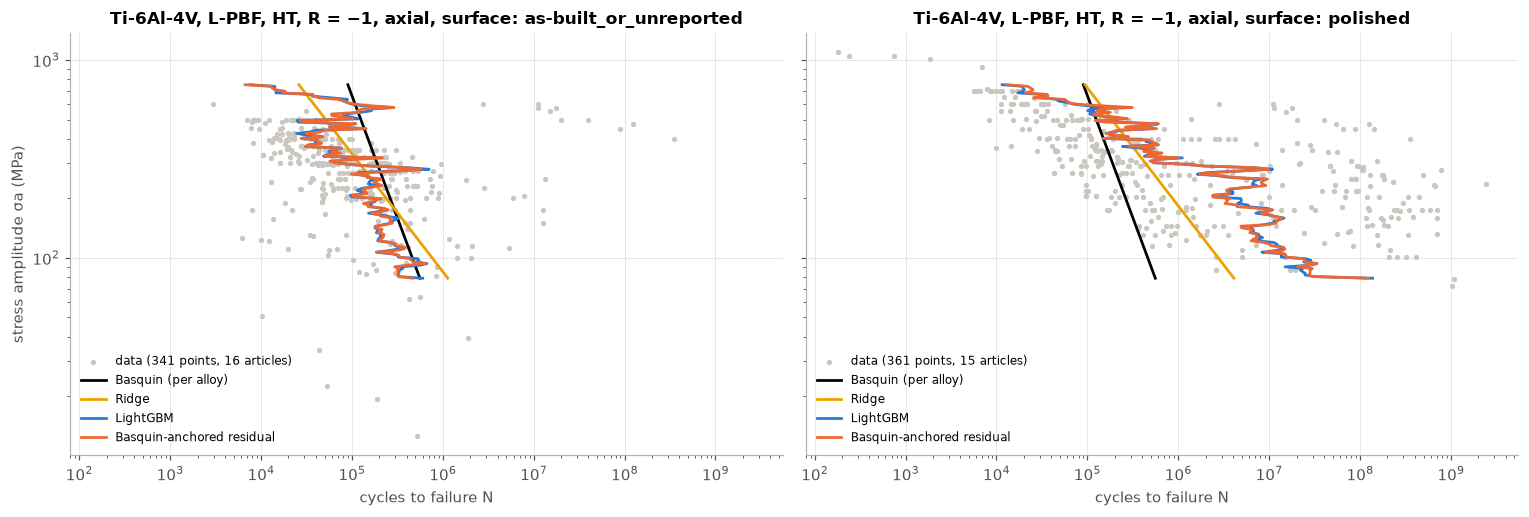

grid steps where life rises with stress          largest single rise (log10 N)           summed rise (log10 N)         
surface                          as-built_or_unreported polished        as-built_or_unreported polished as-built_or_unreported polished
model                                                                                                                                  
Basquin                                             0.0      0.0                         0.000    0.000                  0.000    0.000
BasquinResidual                                    51.0     50.0                         0.585    0.440                  6.129    5.949
LightGBM                                           59.0     52.0                         0.670    0.395                  5.700    5.265
Ridge                                               0.0      0.0                         0.000    0.000                  0.000    0.000

In [15]:
condition = {"R": -1.0, "alloy": "Ti-6Al-4V", "am_process": "L-PBF", "heat_treatment_class": "HT", "test_type_class": "axial"}
subset = data[(data["alloy"] == "Ti-6Al-4V") & (data["am_process"] == "L-PBF") & (data["R"] == -1) & (data["heat_treatment_class"] == "HT") & (data["test_type_class"] == "axial")]
stress = np.logspace(np.log10(subset["stress_amplitude"].quantile(0.01)), np.log10(subset["stress_amplitude"].quantile(0.99)), 120)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharex=True, sharey=True)
monotone_report = []
for ax, surface in zip(axes, ["as-built_or_unreported", "polished"]):
    points = subset[subset["surface_class"] == surface]
    ax.scatter(points["N"], points["stress_amplitude"], s=6, color="#c9c7c0", label=f"data ({len(points):,} points, {points['article_id'].nunique()} articles)", rasterized=True)
    grid = pd.DataFrame({"stress_amplitude": stress, **condition, "surface_class": surface})
    grid = fu.add_stress_features(grid)
    for k, name in enumerate(["Basquin", "Ridge", "LightGBM", "BasquinResidual"]):
        prediction = final_models[name].predict(grid[FEATURES])
        ax.plot(10 ** prediction, stress, lw=1.8, color=["black", eu.PALETTE[3], eu.PALETTE[0], eu.PALETTE[1]][k], label=mu.MODEL_LABELS[name])
        rises = int((np.diff(prediction) > 1e-9).sum())     # steps where predicted life rises as stress rises
        monotone_report.append({"surface": surface, "model": name, "grid steps where life rises with stress": rises, "of": len(stress) - 1,
                                "largest single rise (log10 N)": float(np.clip(np.diff(prediction), 0, None).max()),
                                "summed rise (log10 N)": float(np.clip(np.diff(prediction), 0, None).sum())})
    ax.set(xscale="log", yscale="log", xlabel="cycles to failure N", title=f"Ti-6Al-4V, L-PBF, HT, R = −1, axial, surface: {surface}")
    ax.legend(fontsize=8)
axes[0].set_ylabel("stress amplitude σa (MPa)")
fig.tight_layout()
eu.save_figure(fig, FIG_DIR / "03_predicted_sn_curves_final_models.png")
plt.show()
pd.DataFrame(monotone_report).pivot(index="model", columns="surface", values=["grid steps where life rises with stress", "largest single rise (log10 N)", "summed rise (log10 N)"]).round(3)

Repeat the check for every curve in the dataset, over its own tested stress range.

In [16]:
# The same check for every curve of the dataset: its own test conditions, over its own tested stress range.
condition_columns = ["R", "alloy", "am_process", "surface_class", "heat_treatment_class", "test_type_class"]
curve_range = data.groupby("curve_id").agg(stress_min=("stress_amplitude", "min"), stress_max=("stress_amplitude", "max"),
                                           **{c: (c, "first") for c in condition_columns})
curve_range = curve_range[curve_range["stress_max"] > 1.05 * curve_range["stress_min"]]   # curves tested over more than a 5% stress range
GRID = 30
curve_grid = curve_range.loc[curve_range.index.repeat(GRID)].copy()
position = np.tile(np.linspace(0.0, 1.0, GRID), len(curve_range))
curve_grid["stress_amplitude"] = np.exp(np.log(curve_grid["stress_min"]) + position * (np.log(curve_grid["stress_max"]) - np.log(curve_grid["stress_min"])))
curve_grid = fu.add_stress_features(curve_grid)

monotone_rows = []
for name in mu.MODEL_ORDER:
    prediction = final_models[name].predict(curve_grid[FEATURES]).reshape(len(curve_range), GRID)
    rises = np.clip(np.diff(prediction, axis=1), 0, None)     # upward steps of predicted log10(N) as stress increases
    largest = rises.max(axis=1)
    monotone_rows.append({
        "model": mu.MODEL_LABELS[name], "curves checked": len(curve_range),
        "share of curves with a rise > 0.05": float((largest > 0.05).mean()),
        "share with a rise > 0.2": float((largest > 0.2).mean()),
        "median summed rise (log10 N)": float(np.median(rises.sum(axis=1))),
        "median net fall over the range (log10 N)": float(np.median(prediction[:, 0] - prediction[:, -1])),
        "share with longer life at the top of the range than at the bottom": float((prediction[:, -1] > prediction[:, 0]).mean()),
    })
monotonicity = pd.DataFrame(monotone_rows)
monotonicity.to_csv(METRICS_DIR / "monotonicity_check_final_models.csv", index=False)
monotonicity.round(3)

,model,curves checked,share of curves with a rise > 0.05,share with a rise > 0.2,median summed rise (log10 N),median net fall over the range (log10 N),share with longer life at the top of the range than at the bottom
0,Basquin (per alloy),1455,0.000,0.000,0.000,0.243,0.000
1,Ridge,1455,0.000,0.000,0.000,0.364,0.000
2,Random Forest,1455,0.967,0.737,1.282,0.944,0.043
3,LightGBM,1455,0.958,0.434,0.686,0.642,0.055
4,Basquin-anchored residual,1455,0.968,0.475,0.691,0.665,0.052


*Note:* the in-sample RMSE above is training error, not accuracy. Basquin and Ridge always give falling S-N curves, while the tree models' curves zig-zag on most tested curves, which motivates the monotone run S2.

## 9. Automated leakage tests

Run the tests in `tests/` (group separation, forbidden features, fold rules, saved predictions). The notebook stops if any test fails.

In [17]:
result = subprocess.run([sys.executable, "-m", "pytest", str(PROJECT_ROOT / "tests"), "-v", "--no-header", "--color=no", "-p", "no:cacheprovider"],
                        capture_output=True, text=True, cwd=PROJECT_ROOT)
print(result.stdout[-6000:])
if result.stderr.strip():
    print(result.stderr[-2000:])
(PROJECT_ROOT / "results" / "metrics" / "test_report.txt").write_text(result.stdout, encoding="utf8")
assert result.returncode == 0, "Leakage tests failed"

============================= test session starts =============================
collecting ... collected 42 items

tests/test_audit_checks.py::test_every_saved_fold_table_follows_the_documented_rule PASSED [  2%]
tests/test_audit_checks.py::test_every_prediction_file_covers_each_row_once_and_keeps_groups_together[oof_predictions_ablation.csv] PASSED [  4%]
tests/test_audit_checks.py::test_every_prediction_file_covers_each_row_once_and_keeps_groups_together[oof_predictions_crossfitted_residual.csv] PASSED [  7%]
tests/test_audit_checks.py::test_every_prediction_file_covers_each_row_once_and_keeps_groups_together[oof_predictions_extra_seeds.csv] PASSED [  9%]
tests/test_audit_checks.py::test_every_prediction_file_covers_each_row_once_and_keeps_groups_together[oof_predictions_group_sensitivity.csv] PASSED [ 11%]
tests/test_audit_checks.py::test_every_prediction_file_covers_each_row_once_and_keeps_groups_together[oof_predictions_monotone.csv] PASSED [ 14%]
tests/test_audit_checks.py::test_

## 10. Summary

- With identical data and settings, LightGBM's RMSE is about 0.67 with random splits and 0.92 with articles held out.
- Under random splits almost every test point has its own curve in training, which explains the gap.
- A per-alloy Basquin line fitted to pooled literature data is a weak anchor.
- Out-of-fold predictions, folds and final models are saved for notebook 04.